<a href="https://colab.research.google.com/github/nellyvane23-png/dashboard-financiero-gcp/blob/main/segmentacion_clientes_rfm_ampliado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentación inteligente de clientes con RFM y K-Means
Proyecto reproducible con datos sintéticos. Los resultados no representan clientes reales.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")


## 1. Generación del dataset
Creamos perfiles de compra heterogéneos. La fecha de referencia se fija después del último día de transacciones para evitar dependencia de la fecha actual. Cada fila representa una factura.


In [2]:
n_clientes = 1200
fecha_corte = pd.Timestamp("2026-10-01")
perfiles = rng.choice(["frecuente", "ocasional", "inactivo"], size=n_clientes, p=[.25,.5,.25])
registros = []
for i, perfil in enumerate(perfiles, start=1):
    if perfil == "frecuente":
        n_compras = int(rng.integers(12, 36)); dias = rng.integers(1, 365, n_compras); ticket = 1700
    elif perfil == "ocasional":
        n_compras = int(rng.integers(3, 13)); dias = rng.integers(1, 540, n_compras); ticket = 850
    else:
        n_compras = int(rng.integers(1, 6)); dias = rng.integers(180, 730, n_compras); ticket = 500
    for j, dias_atras in enumerate(dias, start=1):
        categoria = rng.choice(["Tecnologia", "Hogar", "Oficina", "Accesorios"])
        cantidad = int(rng.integers(1, 6))
        precio = round(float(rng.lognormal(np.log(ticket/cantidad), .5)), 2)
        registros.append((f"C{i:04d}", fecha_corte-pd.Timedelta(days=int(dias_atras)), f"F{i:04d}-{j:03d}", categoria, cantidad, precio))
df = pd.DataFrame(registros, columns=["ID_Cliente", "Fecha_Compra", "ID_Factura", "Categoria", "Cantidad", "Precio_Unitario"])
df["Total_Venta"] = (df.Cantidad * df.Precio_Unitario).round(2)
df.to_csv("transacciones_clientes.csv", index=False)
print(df.shape)
display(df.head())


(12391, 7)


,ID_Cliente,Fecha_Compra,ID_Factura,Categoria,Cantidad,Precio_Unitario,Total_Venta
0,C0001,2025-05-28,F0001-001,Oficina,3,569.47,1708.41
1,C0002,2025-09-13,F0002-001,Oficina,2,400.87,801.74
2,C0002,2026-01-23,F0002-002,Hogar,2,407.35,814.70
3,C0002,2026-09-16,F0002-003,Hogar,1,580.71,580.71
4,C0002,2025-12-19,F0002-004,Accesorios,1,1020.80,1020.80


## 2. Control de calidad y exploración
Validamos llaves, valores faltantes y magnitudes; no eliminamos registros silenciosamente.


Nulos por campo:
 ID_Cliente         0
Fecha_Compra       0
ID_Factura         0
Categoria          0
Cantidad           0
Precio_Unitario    0
Total_Venta        0
dtype: int64
Facturas duplicadas: 0


,ID_Cliente,Fecha_Compra,ID_Factura,Categoria,Cantidad,Precio_Unitario,Total_Venta
count,12391,12391,12391,12391,12391.000000,12391.000000,12391.000000
unique,1200,NaN,12391,4,NaN,NaN,NaN
top,C1182,NaN,F1200-003,Accesorios,NaN,NaN,NaN
freq,35,NaN,1,3119,NaN,NaN,NaN
mean,NaN,2026-02-08 16:39:33.077233664,NaN,NaN,3.025180,674.215955,1500.379763
min,NaN,2024-10-02 00:00:00,NaN,NaN,1.000000,18.940000,94.700000
25%,NaN,2025-11-06 00:00:00,NaN,NaN,2.000000,256.090000,789.240000
50%,NaN,2026-02-19 00:00:00,NaN,NaN,3.000000,452.740000,1251.270000
75%,NaN,2026-06-10 00:00:00,NaN,NaN,4.000000,828.235000,1937.980000
max,NaN,2026-09-30 00:00:00,NaN,NaN,5.000000,8595.660000,8876.240000


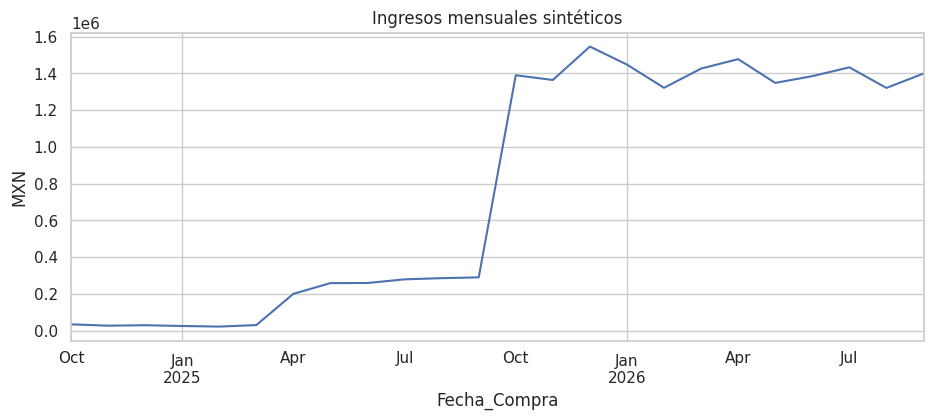

In [3]:
print("Nulos por campo:\n", df.isna().sum())
print("Facturas duplicadas:", df.ID_Factura.duplicated().sum())
assert df.ID_Factura.is_unique
assert (df[["Cantidad", "Precio_Unitario", "Total_Venta"]] > 0).all().all()
assert (df.Fecha_Compra < fecha_corte).all()
display(df.describe(include="all"))
mensual = df.set_index("Fecha_Compra").resample("MS")["Total_Venta"].sum()
mensual.plot(figsize=(11,4), title="Ingresos mensuales sintéticos")
plt.ylabel("MXN"); plt.show()


## 3. Construcción de RFM
Recencia = días desde la última compra; frecuencia = número de facturas; monetario = suma de ingresos. Menor recencia suele indicar mayor actividad.


,Recencia,Frecuencia,Monetario
count,1200.00,1200.00,1200.00
mean,127.27,10.33,15492.67
std,154.74,8.77,19010.59
min,1.00,1.00,147.05
25%,15.00,4.00,2717.74
50%,54.00,8.00,7283.09
75%,207.00,12.00,21302.50
max,723.00,35.00,77522.25


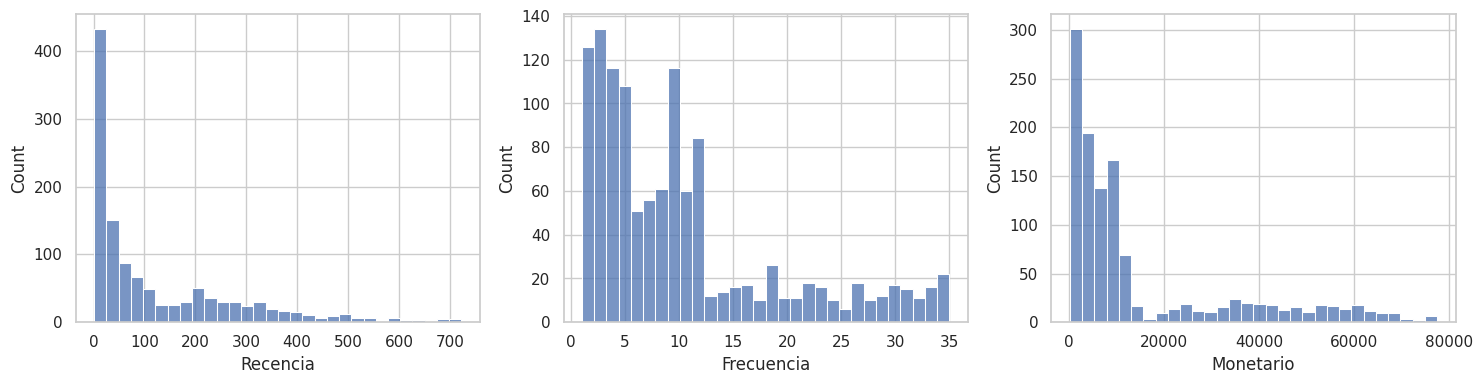

In [4]:
rfm = df.groupby("ID_Cliente").agg(
    Ultima_Compra=("Fecha_Compra", "max"),
    Frecuencia=("ID_Factura", "nunique"),
    Monetario=("Total_Venta", "sum")
)
rfm["Recencia"] = (fecha_corte - rfm.Ultima_Compra).dt.days
rfm = rfm[["Recencia", "Frecuencia", "Monetario"]]
display(rfm.describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, rfm.columns):
    sns.histplot(rfm[col], ax=ax, bins=30)
plt.tight_layout(); plt.show()


## 4. Escalamiento y selección del número de clusters
Usamos log1p para reducir asimetría y StandardScaler para igualar escalas. Silhouette se calcula sobre una muestra reproducible para acelerar la ejecución.


,k,silhouette,inercia
0,2,0.493780,1392.375656
1,3,0.477270,788.115883
2,4,0.437652,625.095506
3,5,0.432972,480.449923
4,6,0.425816,401.572715
5,7,0.407925,340.636366
6,8,0.389894,301.071586


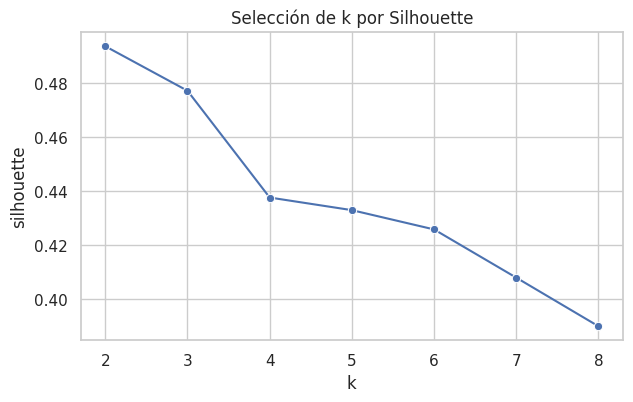

k seleccionado: 2


In [5]:
X_log = np.log1p(rfm[["Recencia", "Frecuencia", "Monetario"]])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
resultados = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    etiquetas = modelo.fit_predict(X)
    score = silhouette_score(X, etiquetas, sample_size=min(1000, len(X)), random_state=SEED)
    resultados.append({"k": k, "silhouette": score, "inercia": modelo.inertia_})
metricas = pd.DataFrame(resultados)
display(metricas)
fig, ax = plt.subplots(figsize=(7,4))
sns.lineplot(data=metricas, x="k", y="silhouette", marker="o", ax=ax)
ax.set_title("Selección de k por Silhouette"); plt.show()
mejor_k = int(metricas.loc[metricas.silhouette.idxmax(), "k"])
print("k seleccionado:", mejor_k)


## 5. Entrenamiento y perfilamiento de segmentos
Las etiquetas numéricas no implican una jerarquía. Interpretamos cada segmento a partir de sus estadísticas observadas.


In [6]:
modelo_final = KMeans(n_clusters=mejor_k, random_state=SEED, n_init=20)
rfm["Cluster"] = modelo_final.fit_predict(X)
resumen = rfm.groupby("Cluster").agg(
    Clientes=("Recencia", "size"),
    Recencia_mediana=("Recencia", "median"),
    Frecuencia_mediana=("Frecuencia", "median"),
    Monetario_mediano=("Monetario", "median"),
    Ingresos=("Monetario", "sum")
).round(2)
resumen["Porcentaje_clientes"] = (100 * resumen.Clientes / len(rfm)).round(1)
display(resumen.sort_values("Ingresos", ascending=False))


,Clientes,Recencia_mediana,Frecuencia_mediana,Monetario_mediano,Ingresos,Porcentaje_clientes
Cluster,,,,,,
0,622,16.0,12.0,18348.56,16729414.22,51.8
1,578,214.0,4.0,2592.93,1861791.42,48.2


## 6. PCA y visualización
PCA reduce a dos dimensiones para visualizar; el modelo se entrena con las tres variables escaladas.


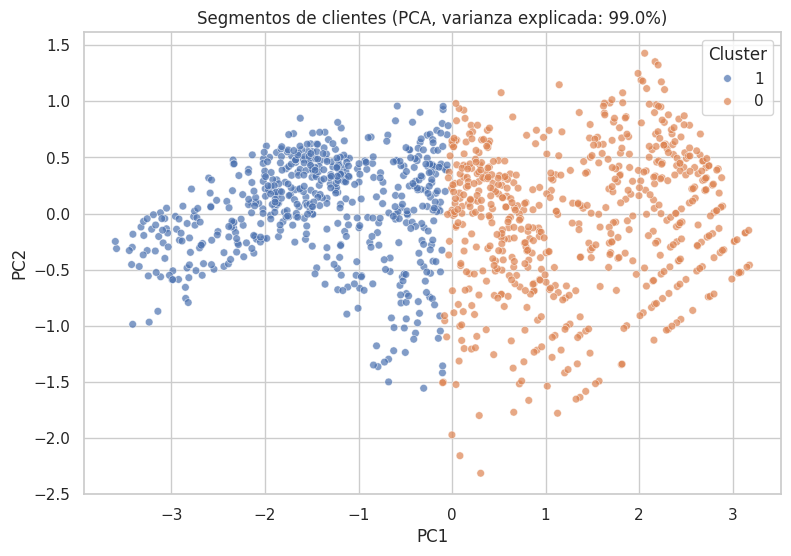

In [7]:
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X)
visual = pd.DataFrame(coordenadas, columns=["PC1", "PC2"], index=rfm.index)
visual["Cluster"] = rfm.Cluster.astype(str)
plt.figure(figsize=(9,6))
sns.scatterplot(data=visual, x="PC1", y="PC2", hue="Cluster", alpha=.7, s=30)
plt.title(f"Segmentos de clientes (PCA, varianza explicada: {pca.explained_variance_ratio_.sum():.1%})")
plt.show()


## 7. Exportación y recomendaciones
Los segmentos con alta recencia requieren estrategias de reactivación; los de baja recencia y alta frecuencia pueden ser candidatos para fidelización. Validar siempre con experimentos comerciales antes de atribuir causalidad.


In [8]:
rfm.reset_index().to_csv("clientes_segmentados.csv", index=False)
resumen.reset_index().to_csv("resumen_segmentos.csv", index=False)
print("Archivos creados: transacciones_clientes.csv, clientes_segmentados.csv, resumen_segmentos.csv")
print("Próximos pasos: estabilidad de clusters, cohortes, CLV y pruebas A/B.")


Archivos creados: transacciones_clientes.csv, clientes_segmentados.csv, resumen_segmentos.csv
Próximos pasos: estabilidad de clusters, cohortes, CLV y pruebas A/B.


## 8. Valor comercial de los segmentos
Comparamos participación de clientes e ingresos. Los clusters son etiquetas arbitrarias, no categorías de negocio predefinidas.


,Clientes,Ingresos,Pct_clientes,Pct_ingresos
Cluster,,,,
0,622,16729414.22,51.83,89.99
1,578,1861791.42,48.17,10.01


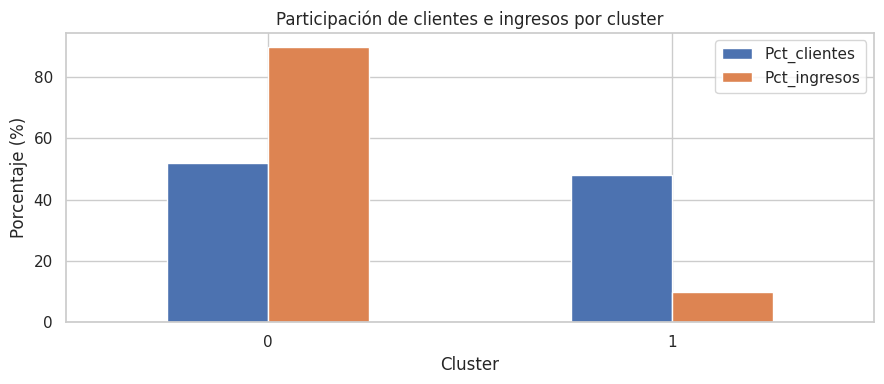

In [9]:
valor = resumen[["Clientes", "Ingresos"]].copy()
valor["Pct_clientes"] = 100 * valor["Clientes"] / valor["Clientes"].sum()
valor["Pct_ingresos"] = 100 * valor["Ingresos"] / valor["Ingresos"].sum()
display(valor.round(2))
valor[["Pct_clientes", "Pct_ingresos"]].plot(kind="bar", figsize=(9, 4))
plt.title("Participación de clientes e ingresos por cluster")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Comparación de dos y tres clusters
Comparamos separación, tamaño y perfiles. La puntuación Silhouette utiliza la misma muestra reproducible del paso 4. No se sustituye automáticamente el modelo base.


In [10]:
comparacion = []
perfiles_comparados = {}
for k in [2, 3]:
    m = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = m.fit_predict(X)
    comparacion.append({
        "k": k,
        "silhouette": silhouette_score(X, labels, sample_size=min(1000, len(X)), random_state=SEED),
        "inercia": m.inertia_,
        "cluster_minimo": pd.Series(labels).value_counts().min()
    })
    temporal = rfm[["Recencia", "Frecuencia", "Monetario"]].copy()
    temporal["Cluster"] = labels
    perfiles_comparados[k] = temporal.groupby("Cluster").agg(
        Clientes=("Recencia", "size"),
        Recencia_mediana=("Recencia", "median"),
        Frecuencia_mediana=("Frecuencia", "median"),
        Monetario_mediano=("Monetario", "median")
    )
display(pd.DataFrame(comparacion).round(4))
for k, perfil in perfiles_comparados.items():
    print(f"Perfiles para k={k}")
    display(perfil.round(2))


,k,silhouette,inercia,cluster_minimo
0,2,0.4938,1392.3757,578
1,3,0.4773,788.1159,311


Perfiles para k=2


,Clientes,Recencia_mediana,Frecuencia_mediana,Monetario_mediano
Cluster,,,,
0,622,16.0,12.0,18348.56
1,578,214.0,4.0,2592.93


Perfiles para k=3


,Clientes,Recencia_mediana,Frecuencia_mediana,Monetario_mediano
Cluster,,,,
0,311,9.0,22.0,42902.28
1,398,279.0,3.0,1910.60
2,491,43.0,8.0,8046.73


## 10. Estabilidad de los segmentos
Comparamos asignaciones de diferentes semillas usando Adjusted Rand Index (ARI), que no depende del número arbitrario asignado a cada cluster.


In [11]:
from sklearn.metrics import adjusted_rand_score
referencia = KMeans(n_clusters=mejor_k, random_state=SEED, n_init=20).fit_predict(X)
filas = []
for semilla in range(10):
    etiquetas = KMeans(n_clusters=mejor_k, random_state=semilla, n_init=20).fit_predict(X)
    filas.append({"semilla": semilla, "ARI": adjusted_rand_score(referencia, etiquetas)})
estabilidad = pd.DataFrame(filas)
display(estabilidad)
print("ARI medio:", round(estabilidad.ARI.mean(), 4))


,semilla,ARI
0,0,0.973489
1,1,0.973489
2,2,0.973489
3,3,0.963639
4,4,0.963639
5,5,0.973489
6,6,0.973489
7,7,0.973489
8,8,0.973489
9,9,0.973489


ARI medio: 0.9715


## 11. Recomendaciones comerciales basadas en perfiles
Las recomendaciones son hipótesis para validar, no efectos causales demostrados. Las etiquetas de negocio se asignan según las medianas observadas.


In [12]:
perfil = rfm.groupby("Cluster")[["Recencia", "Frecuencia", "Monetario"]].median()
for cluster, fila in perfil.iterrows():
    print(f"\nCluster {cluster}: R={fila.Recencia:.0f} días, F={fila.Frecuencia:.0f}, M=${fila.Monetario:,.2f}")
    if fila.Recencia > rfm.Recencia.median():
        print("Hipótesis: evaluar campaña de reactivación y medir recompra frente a grupo control.")
    elif fila.Frecuencia >= rfm.Frecuencia.median() and fila.Monetario >= rfm.Monetario.median():
        print("Hipótesis: probar fidelización y ofertas personalizadas.")
    else:
        print("Hipótesis: probar recomendaciones de productos y acciones de segunda compra.")



Cluster 0: R=16 días, F=12, M=$18,348.56
Hipótesis: probar fidelización y ofertas personalizadas.

Cluster 1: R=214 días, F=4, M=$2,592.93
Hipótesis: evaluar campaña de reactivación y medir recompra frente a grupo control.


## 12. Exportación ampliada y conclusiones
Exportamos indicadores y perfiles adicionales. Los datos son sintéticos y no deben presentarse como evidencia de comportamiento real.


In [13]:
valor.reset_index().to_csv("participacion_segmentos.csv", index=False)
pd.DataFrame(comparacion).to_csv("comparacion_k2_k3.csv", index=False)
estabilidad.to_csv("estabilidad_clusters.csv", index=False)
print("Exportados: participacion_segmentos.csv, comparacion_k2_k3.csv y estabilidad_clusters.csv")
print("Conclusión: contrastar separación, estabilidad e interpretabilidad antes de activar campañas.")


Exportados: participacion_segmentos.csv, comparacion_k2_k3.csv y estabilidad_clusters.csv
Conclusión: contrastar separación, estabilidad e interpretabilidad antes de activar campañas.
